In [11]:
import gymnasium as gym
import numpy as np 
import matplotlib.pyplot as plt
import random
import pickle

In [12]:
# Note: to learn more about the env please check 01 notebook
# Same MC control as frozen lake, but pendulum states and actions are continuous,
# so we put them into discrete bins (a grid) and learn Q for every grid cell

In [13]:
# monte carlo update with sample average
env = gym.make("Pendulum-v1", render_mode=None)

# discretization of state space and action space
num_theta_bins = 51
num_theta_dot_bins = 51
num_action_bins = 5

# arrays for these discrete states and actions
theta_bins = np.linspace(-np.pi, np.pi, num_theta_bins, dtype=np.float32)
theta_dot_bins = np.linspace(-8, 8, num_theta_dot_bins, dtype=np.float32)
action_bins = np.linspace(-2.0, 2.0, num_action_bins, dtype=np.float32)

# hyperparameters
num_episodes = 30000 # num of epi to train
gamma = 0.99
epsilon_start = 1.0 # epsilon is probability for action selection at random
epsilon_end = 0.01
epsilon_decay = 0.000033 # epsilon reaches epsilon_end around the last episode

# action value matrix
Q = np.zeros((num_theta_bins, num_theta_dot_bins, num_action_bins))
Policy = np.zeros((num_theta_bins, num_theta_dot_bins))
# to keep track of how many times this state, action pair is taken
return_count = np.zeros((num_theta_bins, num_theta_dot_bins, num_action_bins))

# returns the index of the action bin, the actual torque is action_bins[action_idx]
def epsilon_greedy_policy(theta_idx, theta_dot_idx, Q, epsilon):
    if random.uniform(0, 1) < epsilon: # explore
        return random.randrange(num_action_bins)

    else:
        return np.argmax(Q[theta_idx, theta_dot_idx]) # choose greedy

for i_episode in range(1, num_episodes + 1):
    episode = [] # to save current episode history
    state, info = env.reset()
    terminated = False
    truncated = False

    # Epsilon decay
    epsilon = max(epsilon_end, epsilon_start - epsilon_decay*i_episode)

    # collect one episode
    while (not terminated and not truncated):
        # the observation = [cos(theta), sin(theta), theta_dot]
        theta = np.arctan2(state[1], state[0])
        theta_idx = np.digitize(theta, theta_bins) - 1

        theta_dot = state[2]
        theta_dot_idx = np.digitize(theta_dot, theta_dot_bins) - 1

        action_idx = epsilon_greedy_policy(theta_idx, theta_dot_idx, Q, epsilon)
        action = action_bins[action_idx]

        next_state, reward, terminated, truncated, info = env.step([action])

        # store the state, action, reward
        episode.append((theta_idx, theta_dot_idx, action_idx, reward))

        state = next_state

    # monte carlo update
    G = 0 # total return for current episode

    for t in reversed(range(len(episode))):
        # start with last (s, a, r) pair
        theta_idx_t, theta_dot_idx_t, action_idx_t, reward_t = episode[t]

        # update the total return
        G = reward_t + gamma * G

        # for every visit counter
        return_count[theta_idx_t, theta_dot_idx_t, action_idx_t] += 1.0

        # update Q values
        Q[theta_idx_t, theta_dot_idx_t, action_idx_t] += (1/return_count[theta_idx_t, theta_dot_idx_t, action_idx_t]) * (G - Q[theta_idx_t, theta_dot_idx_t, action_idx_t])

    # progress report
    if i_episode % 1000 == 0:
        print(f"\nEpisode {i_episode}/{num_episodes}, Epsilon: {epsilon:.4f}")

        Policy = np.argmax(Q, axis=2)

        # Evaluate the learned policy
        print("Evaluating learned policy...")
        total_rewards = 0
        num_eval_episodes = 100

        for _ in range(num_eval_episodes):
            state, info = env.reset()
            terminated = False
            truncated = False
            episode_reward = 0

            while (not terminated and not truncated):
                # the observation = [cos(theta), sin(theta), theta_dot]
                theta = np.arctan2(state[1], state[0])
                theta_idx = np.digitize(theta, theta_bins) - 1

                theta_dot = state[2]
                theta_dot_idx = np.digitize(theta_dot, theta_dot_bins) - 1

                # For evaluation, use a greedy policy (no exploration)
                action_idx = Policy[theta_idx, theta_dot_idx]
                action = action_bins[action_idx]
                next_state, reward, terminated, truncated, info = env.step([action])
                episode_reward += reward
                state = next_state

            total_rewards += episode_reward

        print(f"Average reward over {num_eval_episodes} evaluation episodes: {total_rewards / num_eval_episodes:.4f}")

env.close()
# best policy
Policy = np.argmax(Q, axis=2)


Episode 1000/30000, Epsilon: 0.9670
Evaluating learned policy...
Average reward over 100 evaluation episodes: -469.7591

Episode 2000/30000, Epsilon: 0.9340
Evaluating learned policy...
Average reward over 100 evaluation episodes: -723.7873

Episode 3000/30000, Epsilon: 0.9010
Evaluating learned policy...
Average reward over 100 evaluation episodes: -574.6446

Episode 4000/30000, Epsilon: 0.8680
Evaluating learned policy...
Average reward over 100 evaluation episodes: -687.5741

Episode 5000/30000, Epsilon: 0.8350
Evaluating learned policy...
Average reward over 100 evaluation episodes: -295.9347

Episode 6000/30000, Epsilon: 0.8020
Evaluating learned policy...
Average reward over 100 evaluation episodes: -274.8818

Episode 7000/30000, Epsilon: 0.7690
Evaluating learned policy...
Average reward over 100 evaluation episodes: -270.4036

Episode 8000/30000, Epsilon: 0.7360
Evaluating learned policy...
Average reward over 100 evaluation episodes: -244.8584

Episode 9000/30000, Epsilon: 0.

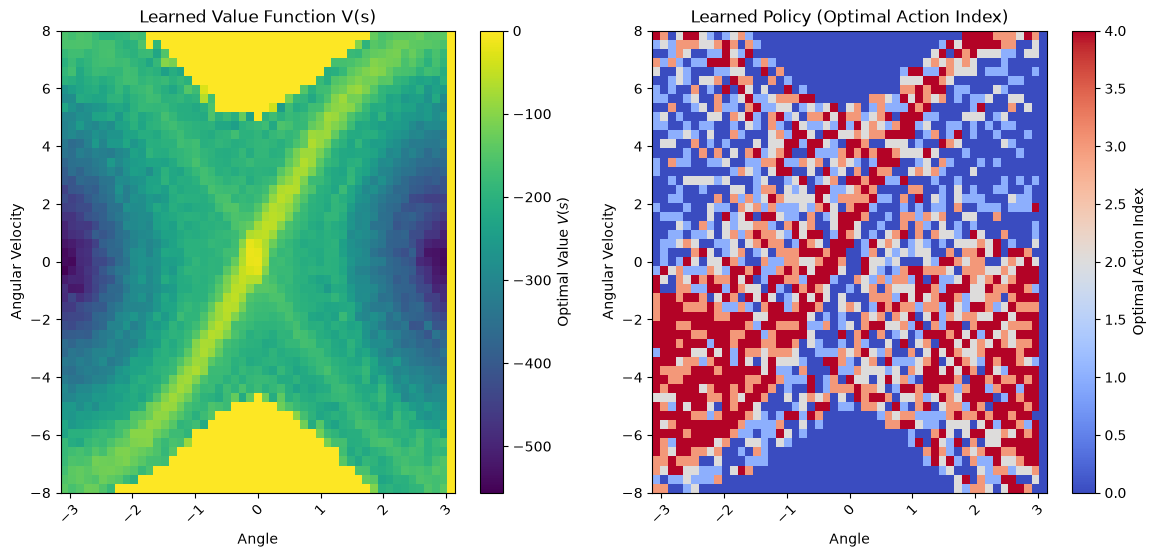

In [14]:
# plotting the value function and policy
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
plt.imshow(np.max(Q, axis=2).T, cmap='viridis',   # V.T because V(num_theta_bins, num_theta_dot_bins) goes to (y , x)
           extent=[theta_bins.min(), theta_bins.max(), theta_dot_bins.min(), theta_dot_bins.max()],
           aspect='auto')
plt.colorbar(label='Optimal Value $V(s)$')
plt.xlabel('Angle')
plt.ylabel('Angular Velocity') 
plt.title('Learned Value Function V(s)')
plt.xticks(rotation=45) # x axis label rotation

plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
plt.imshow(Policy.T, cmap='coolwarm',
           extent=[theta_bins.min(), theta_bins.max(), theta_dot_bins.min(), theta_dot_bins.max()],
           aspect='auto')
plt.colorbar(label='Optimal Action Index')
plt.xlabel('Angle')
plt.ylabel('Angular Velocity')
plt.title('Learned Policy (Optimal Action Index)')
plt.xticks(rotation=45)

plt.show()

In [15]:
# Save the learned action value function and policy
policy_filename = 'pendulum_monte_carlo_policy.pkl'
with open(policy_filename, 'wb') as f:
    pickle.dump({'Q': Q, 'Policy': Policy}, f)

print(f"Policy and action value function saved to {policy_filename}")

Policy and action value function saved to pendulum_monte_carlo_policy.pkl


In [16]:
import os
# open the saved policy
policy_filename = 'pendulum_monte_carlo_policy.pkl'

Q = None
Policy = None

if os.path.exists(policy_filename):
    with open(policy_filename, 'rb') as f:
        loaded_data = pickle.load(f)
        Q = loaded_data['Q']
        Policy = loaded_data['Policy']
    print(f"Policy and action value function loaded from {policy_filename}")
else:
    print(f"Error: Policy file '{policy_filename}' not found. Please run the training code first.")

Policy and action value function loaded from pendulum_monte_carlo_policy.pkl


In [17]:
# Evaluate the learned policy
env = gym.make("Pendulum-v1", render_mode='human')

print("Evaluating learned policy...")
total_rewards = 0
num_eval_episodes = 5

for _ in range(num_eval_episodes):
    state, info = env.reset()
    terminated = False
    truncated = False
    episode_reward = 0

    while (not terminated and not truncated):
        # the observation = [cos(theta), sin(theta), theta_dot]
        theta = np.arctan2(state[1], state[0])
        theta_idx = np.digitize(theta, theta_bins) - 1

        theta_dot = state[2]
        theta_dot_idx = np.digitize(theta_dot, theta_dot_bins) - 1

        # For evaluation, use a greedy policy (no exploration)
        action_idx = Policy[theta_idx, theta_dot_idx]
        action = action_bins[action_idx]
        next_state, reward, terminated, truncated, info = env.step([action])
        episode_reward += reward
        state = next_state

    total_rewards += episode_reward
print(f"Average reward over {num_eval_episodes} evaluation episodes: {total_rewards / num_eval_episodes:.4f}")
env.close()



Evaluating learned policy...
Average reward over 5 evaluation episodes: -222.5667
